# High Power — Blade Design Notebook

A notebook port of the `/design/blades` pages from the web app:

1. **Blades overview** — rotating turbine, blade-count slider, stats and power curve (`SubsystemOverview.tsx`)
2. **Blade design detail** — spinning rotor, airfoil cross-section with angle of attack, wireframe blade planform (`BladeDetail.tsx`)
3. **Pure-Python analysis** — matplotlib plots and an animated airfoil sweep

The interactive panels are self-contained HTML/SVG/JS rendered from Python, so they animate smoothly in both local Jupyter and Google Colab with no extra installs. The physics lives in Python (cell 1) and is passed into the panels; the detail panel mirrors the same formulas in JS so the sliders update live.

**Colab:** File → Upload notebook, then Runtime → Run all.

In [1]:
# ── Setup: parameters & physics (Python is the source of truth) ──
import json, uuid, math
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML, display

# Blade defaults — mirrors backend/app/models/blade.py
BLADE = dict(
    blade_length_m=56.0,
    max_chord_m=4.2,
    root_chord_m=3.0,
    total_twist_deg=13.0,
    design_tip_speed_ratio=8.0,
    mass_kg=12000.0,
    material="fiberglass",
    airfoil_family="NREL S-series",
)

RHO = 1.225          # air density, kg/m^3
TSR = 8              # tip speed ratio
CUT_IN_WIND = 4      # m/s
RATED_WIND = 13      # m/s
RATED_POWER_MW = 2.0
OVERVIEW_RPM = 8     # fixed display RPM on the overview page
DEFAULT_WIND = 10.0  # m/s (the app starts at 0; 10 makes the demo spin)


# ── Overview (blade count) model — from frontend/src/data/subsystems.ts ──
def blade_count_scale(n):
    return 1 - abs(n - 3) * 0.06

def power_curve(n):
    s = blade_count_scale(n)
    out = []
    for wind in range(26):
        if CUT_IN_WIND <= wind < RATED_WIND:
            f = (wind - CUT_IN_WIND) / (RATED_WIND - CUT_IN_WIND)
            p = RATED_POWER_MW * s * f**3
        elif wind >= RATED_WIND:
            p = RATED_POWER_MW * s
        else:
            p = 0.0
        out.append((wind, round(p, 3)))
    return out

def overview_stats(n):
    s = blade_count_scale(n)
    return {
        "Weight": f"{20 + (n - 3) * 2.5:.1f} t",
        "Cost": f"{1200 + (n - 3) * 60}k",
        "Avg Output": f"{2.0 * s:.2f} MW",
        "Efficiency": f"{round(s * 100)}%",
    }


# ── Blade section model — from BladeDetail.tsx ──
def lift_coefficient(aoa_deg):
    """Thin-airfoil theory Cl = 2*pi*alpha, clamped to [0, 1.8]."""
    return float(np.clip(2 * np.pi * np.radians(aoa_deg), 0, 1.8))

def blade_physics(aoa_deg, wind, length_m, chord_m, n_sections=10):
    cl = lift_coefficient(aoa_deg)
    q = 0.5 * RHO * wind**2
    omega = TSR * wind / length_m if length_m > 0 else 0.0
    seg = length_m / n_sections
    r = (np.arange(n_sections) + 0.5) / n_sections
    area = chord_m * (1 - r**2) * seg          # chord tapers ~ (1 - r^2)
    lift = q * area * cl
    drag = q * area * (0.05 + 0.1 * cl**2)
    weight = 8 * length_m * chord_m
    return {
        "cl": cl,
        "pressure_diff_pa": q * cl,
        "resultant_vel": wind * (1 + 0.4 * cl),
        "tip_speed": TSR * wind,
        "rpm": omega * 60 / (2 * np.pi),
        "total_lift_n": float(lift.sum()),
        "total_drag_n": float(drag.sum()),
        "weight_kg": weight,
        "cost_usd": weight * 200,
    }

blade_physics(8, DEFAULT_WIND, BLADE["blade_length_m"], BLADE["max_chord_m"])

{'cl': 0.8772981689857208,
 'pressure_diff_pa': 53.7345128503754,
 'resultant_vel': 13.509192675942883,
 'tip_speed': 80.0,
 'rpm': 13.641852265019603,
 'total_lift_n': 8436.103579457536,
 'total_drag_n': 1220.8980723631985,
 'weight_kg': 1881.6000000000001,
 'cost_usd': 376320.0}

In [2]:
# ── Shared matrix-style theme for the HTML panels ──
THEME_CSS = """
.hp { background:#000; color:#00ff41; font-family: ui-sans-serif, system-ui, -apple-system, sans-serif;
      border-radius:16px; padding:16px; user-select:none; box-sizing:border-box; }
.hp * { box-sizing:border-box; }
.hp .grid { display:grid; grid-template-columns: 1fr 2fr 1fr; gap:12px; }
@media (max-width: 760px) { .hp .grid { grid-template-columns: 1fr; } }
.hp .panel { background:rgba(0,255,65,0.05); border:1px solid rgba(0,255,65,0.2); border-radius:16px; padding:10px; }
.hp .out { background:rgba(0,255,65,0.1); border:1px solid rgba(0,255,65,0.3); border-radius:12px;
           padding:6px 10px; text-align:center; margin-bottom:6px; }
.hp .out .k { font-size:11px; text-transform:uppercase; letter-spacing:.05em; color:rgba(0,255,65,0.55); }
.hp .out .v { font-size:16px; font-weight:700; }
.hp .col { display:flex; flex-direction:column; gap:8px; min-width:0; }
.hp .row { display:flex; justify-content:space-between; align-items:center; font-size:13px; }
.hp .hint { display:flex; justify-content:space-between; font-size:11px; color:rgba(0,255,65,0.4); }
.hp .dim { color:rgba(0,255,65,0.55); }
.hp input[type=range] { width:100%; accent-color:#00ff41; }
.hp button { background:rgba(0,255,65,0.08); border:1px solid rgba(0,255,65,0.35); color:#00ff41;
             border-radius:8px; padding:2px 10px; font-weight:700; cursor:pointer; }
.hp button:hover { background:rgba(0,255,65,0.18); }
.hp svg { width:100%; height:auto; display:block; }
.hp h3 { margin:0 0 10px; font-size:15px; font-weight:600; }
"""

def render_panel(html, js, data):
    """Render an HTML/JS panel with a unique id so re-runs don't collide."""
    pid = "hp-" + uuid.uuid4().hex[:8]
    page = (f"<style>{THEME_CSS}</style>"
            f"<div id='{pid}' class='hp'>{html}</div>"
            f"<script>(function(){{const ROOT=document.getElementById('{pid}');"
            f"const PID='{pid}';const DATA={json.dumps(data)};{js}}})();</script>")
    display(HTML(page))

## 1 · Blades overview

Drag the slider to change the number of blades. Stats and the power curve come from `overview_stats()` / `power_curve()` in Python.

In [3]:
OVERVIEW_HTML = """
<h3>Blades</h3>
<div class="grid">
  <div class="col" style="justify-content:center" data-stats></div>
  <div class="panel">
    <svg viewBox="0 0 1000 700">
      <polygon points="200,700 500,350 800,700" fill="#001a00"/>
      <polygon points="50,700 350,420 650,700" fill="#001000"/>
      <polygon points="488,380 512,380 508,620 492,620" fill="#001500" stroke="rgba(0,255,65,0.4)"/>
      <rect x="496" y="204" width="8" height="176" rx="2" fill="#001500" stroke="rgba(0,255,65,0.3)" stroke-width="0.5"/>
      <rect x="482" y="188" width="36" height="18" rx="4" fill="#001a00" stroke="rgba(0,255,65,0.5)"/>
      <circle cx="500" cy="200" r="9" fill="#001800" stroke="#00ff41"/>
      <circle cx="500" cy="200" r="6" fill="#002500"/>
      <g data-rotor></g>
      <circle cx="500" cy="200" r="5" fill="#001800" stroke="rgba(0,255,65,0.6)"/>
      <rect x="0" y="620" width="1000" height="80" fill="#001000"/>
    </svg>
  </div>
  <div class="panel col">
    <div class="dim" style="font-size:12px;text-align:center">Power Curve (MW)</div>
    <svg viewBox="0 0 260 200" data-curve></svg>
    <div class="dim" style="font-size:11px;text-align:center;opacity:.7">Wind speed (m/s)</div>
  </div>
</div>
<div class="panel" style="max-width:480px;margin:12px auto 0">
  <div class="row"><span>Blades: <b style="font-size:18px" data-n></b></span><span class="dim" data-caption></span></div>
  <input type="range" min="1" max="6" step="1" value="3" data-slider>
  <div class="hint"><span>1 blade</span><span>3 = optimal</span><span>6 blades</span></div>
</div>
"""

OVERVIEW_JS = r"""
const q = s => ROOT.querySelector(s);
const rotor = q('[data-rotor]'), slider = q('[data-slider]');
const BLADE_D = 'M496,200 Q493,110 500,40 Q507,110 504,200 Z';

function drawCurve(curve) {
  const x0=30, x1=250, y0=10, y1=180, X=w=>x0+(w/25)*(x1-x0), Y=p=>y1-(p/2)*(y1-y0);
  let g = '';
  for (let w=0; w<=25; w+=5) g += `<line x1="${X(w)}" y1="${y0}" x2="${X(w)}" y2="${y1}" stroke="rgba(0,255,65,0.12)" stroke-dasharray="3 3"/>`
     + `<text x="${X(w)}" y="195" fill="rgba(0,255,65,0.5)" font-size="10" text-anchor="middle">${w}</text>`;
  for (let p=0; p<=2; p+=0.5) g += `<line x1="${x0}" y1="${Y(p)}" x2="${x1}" y2="${Y(p)}" stroke="rgba(0,255,65,0.12)" stroke-dasharray="3 3"/>`
     + `<text x="${x0-5}" y="${Y(p)+3}" fill="rgba(0,255,65,0.5)" font-size="10" text-anchor="end">${p}</text>`;
  const pts = curve.map(([w,p]) => `${X(w).toFixed(1)},${Y(p).toFixed(1)}`).join(' ');
  q('[data-curve]').innerHTML = g + `<polyline points="${pts}" fill="none" stroke="#00ff41" stroke-width="2"/>`;
}

function update() {
  const n = +slider.value, d = DATA.byN[n];
  rotor.innerHTML = Array.from({length:n}, (_,i) =>
    `<g transform="rotate(${i*360/n} 500 200)"><path d="${BLADE_D}" fill="rgba(0,255,65,0.07)" stroke="#00ff41"/></g>`).join('');
  q('[data-stats]').innerHTML = Object.entries(d.stats).map(([k,v]) =>
    `<div class="out panel"><div class="k">${k}</div><div class="v" style="font-size:18px">${v}</div></div>`).join('');
  q('[data-n]').textContent = n;
  q('[data-caption]').textContent = n===3 ? 'Optimal aerodynamic balance' : n<3 ? 'Higher RPM, lower torque' : 'More torque, more drag';
  drawCurve(d.curve);
}
slider.addEventListener('input', update);
update();

let angle = 0, last = null;
function frame(t) {
  if (!document.body.contains(ROOT)) return;   // stop when cell is re-run/cleared
  if (last !== null) angle = (angle + DATA.rpm * 6 * (t - last) / 1000) % 360;
  last = t;
  rotor.setAttribute('transform', `rotate(${angle} 500 200)`);
  requestAnimationFrame(frame);
}
requestAnimationFrame(frame);
"""

overview_data = {
    "rpm": OVERVIEW_RPM,
    "byN": {n: {"stats": overview_stats(n), "curve": power_curve(n)} for n in range(1, 7)},
}
render_panel(OVERVIEW_HTML, OVERVIEW_JS, overview_data)

## 2 · Blade design detail

- **Left:** rotor spinning at the RPM implied by wind speed, TSR and blade length
- **Center:** airfoil cross-section. Angle of attack tilts the section, streamlines flow at a speed proportional to wind, lift arrows scale with $C_L$
- **Right:** wireframe blade (ribs + stringers). The vertical slider highlights a radial section; ↑/↓ change chord and length

Defaults come from the `BLADE` dict. The JS uses the same formulas as `blade_physics()`.

In [4]:
DETAIL_HTML = """
<h3>Blade Design</h3>
<div class="grid">
  <!-- LEFT: rotating turbine + outputs -->
  <div class="col">
    <div class="panel">
      <svg viewBox="0 0 300 250">
        <polygon points="60,220 150,125 240,220" fill="#001a00"/>
        <polygon points="10,220 110,145 200,220" fill="#001000"/>
        <polygon points="144,148 156,148 154,215 146,215" fill="#001500" stroke="rgba(0,255,65,0.4)"/>
        <rect x="139" y="110" width="22" height="11" rx="3" fill="#001a00" stroke="rgba(0,255,65,0.5)"/>
        <circle cx="150" cy="117" r="7" fill="#001800" stroke="#00ff41"/>
        <circle cx="150" cy="117" r="4.5" fill="#002500"/>
        <g data-rotor>
          <g transform="rotate(0 150 117)"><path d="M146,117 Q143,70 150,22 Q157,70 154,117 Z" fill="rgba(0,255,65,0.07)" stroke="#00ff41"/></g>
          <g transform="rotate(120 150 117)"><path d="M146,117 Q143,70 150,22 Q157,70 154,117 Z" fill="rgba(0,255,65,0.07)" stroke="#00ff41"/></g>
          <g transform="rotate(240 150 117)"><path d="M146,117 Q143,70 150,22 Q157,70 154,117 Z" fill="rgba(0,255,65,0.07)" stroke="#00ff41"/></g>
        </g>
        <circle cx="150" cy="117" r="3" fill="#001800" stroke="rgba(0,255,65,0.6)"/>
        <rect x="0" y="215" width="300" height="35" fill="#001000"/>
      </svg>
    </div>
    <div data-left-out></div>
  </div>

  <!-- CENTER: airfoil + controls -->
  <div class="col">
    <svg viewBox="0 0 900 420" data-airfoil></svg>
    <div class="panel">
      <div class="row"><span>Angle of Attack</span><b data-aoa-v></b></div>
      <input type="range" min="0" max="20" step="1" data-aoa>
      <div class="hint"><span>0° (no lift)</span><span>20° (near stall)</span></div>
      <div class="row" style="margin-top:10px"><span>Wind Speed</span><b data-wind-v></b></div>
      <input type="range" min="0" max="25" step="0.5" data-wind>
      <div class="hint"><span>0 m/s</span><span>25 m/s</span></div>
    </div>
  </div>

  <!-- RIGHT: blade wireframe + size controls + outputs -->
  <div class="col">
    <div class="panel" style="display:flex;gap:6px">
      <div style="flex:1;min-width:0"><svg viewBox="0 0 120 310" data-blade style="max-height:380px"></svg></div>
      <div style="display:flex;flex-direction:column;align-items:center;justify-content:center;gap:6px;font-size:11px">
        <span class="dim">tip</span>
        <input type="range" min="0" max="9" step="1" data-sec
               style="writing-mode:vertical-lr;direction:rtl;height:140px;width:auto;cursor:pointer">
        <span class="dim">root</span>
        <b data-sec-v></b>
      </div>
    </div>
    <div class="panel" style="font-size:12px">
      <div class="row" style="margin-bottom:6px"><span class="dim">Blade width: <b style="color:#00ff41" data-width-v></b></span>
        <span><button data-w="+">↑</button> <button data-w="-">↓</button></span></div>
      <div class="row"><span class="dim">Blade length: <b style="color:#00ff41" data-len-v></b></span>
        <span><button data-l="+">↑</button> <button data-l="-">↓</button></span></div>
    </div>
    <div data-right-out></div>
  </div>
</div>
"""

DETAIL_JS = r"""
const q = s => ROOT.querySelector(s);
const RHO = DATA.rho, TSR = DATA.tsr, PX = 440, PY = 195;
const S = { aoa: 8, wind: DATA.wind, sec: 5, len: DATA.length, width: DATA.chord };
const fmt = n => Math.round(n).toLocaleString();
const out = items => items.map(([k,v]) => `<div class="out"><div class="k">${k}</div><div class="v">${v}</div></div>`).join('');

function arc(cx, cy, r, a0, a1) {
  const t = d => d*Math.PI/180;
  return `M ${cx+r*Math.cos(t(a0))},${cy+r*Math.sin(t(a0))} A ${r},${r} 0 0,1 ${cx+r*Math.cos(t(a1))},${cy+r*Math.sin(t(a1))}`;
}
function stream(dy, aoa, upper) {
  const y = PY + dy, prox = Math.max(0, 1 - Math.abs(dy)/165);
  const def = upper ? prox*aoa*4 : prox*aoa*1.5, sg = upper ? -1 : 1;
  return `M 30,${y} C 200,${y+sg*def*0.5} 680,${y+sg*def} 870,${y}`;
}

function physics() {
  const aoaRad = S.aoa*Math.PI/180;
  const cl = Math.max(0, Math.min(2*Math.PI*aoaRad, 1.8));
  const q = 0.5*RHO*S.wind**2;
  const omega = S.len > 0 ? TSR*S.wind/S.len : 0;
  let lift = 0;
  for (let i = 0; i < 10; i++) { const r = (i+0.5)/10; lift += q*S.width*(1-r*r)*(S.len/10)*cl; }
  const weight = 8*S.len*S.width;
  return { aoaRad, cl, pdiff: q*cl, vres: S.wind*(1+0.4*cl), vtip: TSR*S.wind,
           rpm: omega*60/(2*Math.PI), lift, weight, cost: weight*200 };
}

function drawAirfoil(p) {
  const M = PID, a = S.aoa;
  const liftPx = Math.min((p.cl/1.8)*80*Math.min(S.wind/10, 2), 90);
  const windLen = Math.min(S.wind*6.5, 160);
  // streamlines flow: dash period 20px, speed ∝ wind
  const dur = S.wind > 0 ? (20 / (S.wind*12)).toFixed(3) + 's' : '0s';
  const play = S.wind > 0 ? 'running' : 'paused';
  const sl = (dy, up) => `<path d="${stream(dy, a, up)}" fill="none" stroke="rgba(0,255,65,${up?0.45:0.25})"
      stroke-width="${up?1.5:1.2}" stroke-dasharray="12 8" marker-end="url(#${M}-sa)"
      style="animation:${M}-flow ${dur} linear infinite;animation-play-state:${play}"/>`;
  let s = `<style>@keyframes ${M}-flow { to { stroke-dashoffset: -20; } }</style>
  <defs>
    <marker id="${M}-sa" viewBox="0 0 6 6" markerWidth="5" markerHeight="5" refX="5" refY="3" orient="auto"><path d="M0,0 L6,3 L0,6 Z" fill="rgba(0,255,65,0.6)"/></marker>
    <marker id="${M}-wa" viewBox="0 0 6 6" markerWidth="5" markerHeight="5" refX="5" refY="3" orient="auto"><path d="M0,0 L6,3 L0,6 Z" fill="#00ff41"/></marker>
    <marker id="${M}-la" viewBox="0 0 6 6" markerWidth="5" markerHeight="5" refX="3" refY="0" orient="auto"><path d="M0,6 L3,0 L6,6 Z" fill="#00ff41"/></marker>
  </defs>`;
  s += [-130,-80,-42].map(dy => sl(dy, true)).join('') + [42,82,125].map(dy => sl(dy, false)).join('');
  if (windLen > 4) s += [-100,-50,0,50,100].map(dy =>
      `<line x1="50" y1="${PY+dy}" x2="${50+windLen}" y2="${PY+dy}" stroke="rgba(0,255,65,0.7)" stroke-width="2" marker-end="url(#${M}-wa)"/>`).join('');
  if (liftPx > 4) s += [355,410,465,520,575].map(x =>
      `<line x1="${x}" y1="275" x2="${x}" y2="${275-liftPx}" stroke="#00ff41" stroke-width="2.5" marker-end="url(#${M}-la)"/>`).join('')
      + `<text x="465" y="292" fill="#00ff41" font-size="12" font-weight="600" text-anchor="middle" opacity="0.85">Lift</text>`;
  s += `<g transform="rotate(${-a}, ${PX}, ${PY})">
      <line x1="370" y1="195" x2="650" y2="195" stroke="rgba(0,255,65,0.3)" stroke-dasharray="4 4"/>
      <path d="M 370,195 C 390,145 468,121 538,133 C 602,145 638,171 650,195 C 638,207 598,213 538,209 C 468,205 390,200 370,195 Z"
            fill="rgba(0,255,65,0.06)" stroke="#00ff41" stroke-width="1.5"/>
      <text x="510" y="183" fill="rgba(0,255,65,0.85)" font-size="13" font-weight="600" text-anchor="middle">Curved Blade</text>
    </g>
    <line x1="320" y1="${PY}" x2="368" y2="${PY}" stroke="rgba(0,255,65,0.5)" stroke-width="1.5" stroke-dasharray="4 3"/>
    <line x1="320" y1="${PY}" x2="${320+48*Math.cos(-p.aoaRad)}" y2="${PY+48*Math.sin(-p.aoaRad)}" stroke="#00ff41" stroke-width="2"/>
    ${a > 0 ? `<path d="${arc(320, PY, 28, -a, 0)}" fill="none" stroke="#00ff41" stroke-width="1.2" opacity="0.8"/>` : ''}
    <text x="285" y="${PY+28}" fill="rgba(0,255,65,0.7)" font-size="11" text-anchor="middle">Angle of</text>
    <text x="285" y="${PY+41}" fill="rgba(0,255,65,0.7)" font-size="11" text-anchor="middle">Attack</text>
    <text x="65" y="${PY-118}" fill="rgba(0,255,65,0.7)" font-size="13" font-weight="600">Wind</text>
    <text x="730" y="100" fill="rgba(0,255,65,0.75)" font-size="13" text-anchor="middle">Low Pressure</text>
    <text x="710" y="340" fill="rgba(0,255,65,0.45)" font-size="13" text-anchor="middle">High Pressure</text>`;
  q('[data-airfoil]').innerHTML = s;
}

function drawBlade() {
  const maxC = Math.min(S.width*12, 54), top = 20, root = 290, span = root - top, N = 14;
  const secs = Array.from({length:N}, (_,i) => {
    const t = i/(N-1), hc = Math.max(1.5, maxC*(1-t*t)/2);
    return { y: root - t*span, hc, ry: Math.max(1.8, hc*(0.7 - t*0.65)), hi: Math.round(t*9) === S.sec };
  });
  const line = f => secs.map((s,i) => `${i?'L':'M'}${f(s).toFixed(1)},${s.y.toFixed(1)}`).join(' ');
  const fill = line(s => 60-s.hc) + ' ' + [...secs].reverse().map(s => `L${(60+s.hc).toFixed(1)},${s.y.toFixed(1)}`).join(' ') + ' Z';
  q('[data-blade]').innerHTML = `
    <path d="${fill}" fill="rgba(0,255,65,0.03)"/>
    <path d="${line(s=>60-s.hc)}" fill="none" stroke="rgba(0,255,65,0.65)" stroke-width="1.2"/>
    <path d="${line(s=>60+s.hc)}" fill="none" stroke="rgba(0,255,65,0.65)" stroke-width="1.2"/>
    <path d="${line(s=>60-s.hc*0.5)}" fill="none" stroke="rgba(0,255,65,0.22)" stroke-width="0.7" stroke-dasharray="3 3"/>
    <path d="${line(s=>60+s.hc*0.5)}" fill="none" stroke="rgba(0,255,65,0.22)" stroke-width="0.7" stroke-dasharray="3 3"/>
    ${secs.map(s => `<ellipse cx="60" cy="${s.y}" rx="${s.hc}" ry="${s.ry}" fill="${s.hi?'rgba(0,255,65,0.12)':'none'}"
        stroke="${s.hi?'#00ff41':'rgba(0,255,65,0.38)'}" stroke-width="${s.hi?1.5:0.8}"/>`).join('')}
    <circle cx="60" cy="${top}" r="2" fill="#00ff41" opacity="0.7"/>
    <text x="60" y="307" fill="rgba(0,255,65,0.5)" font-size="9" text-anchor="middle">root</text>
    <text x="60" y="15" fill="rgba(0,255,65,0.5)" font-size="9" text-anchor="middle">tip</text>`;
}

let rpm = 0;
function update() {
  const p = physics(); rpm = p.rpm;
  drawAirfoil(p); drawBlade();
  q('[data-aoa-v]').textContent = S.aoa + '°';
  q('[data-wind-v]').textContent = S.wind + ' m/s';
  q('[data-sec-v]').textContent = (S.sec+1) + '/10';
  q('[data-width-v]').textContent = S.width + 'm';
  q('[data-len-v]').textContent = S.len + 'm';
  q('[data-left-out]').innerHTML = out([['Tip Speed', p.vtip.toFixed(1)+' m/s'], ['RPM', p.rpm.toFixed(1)],
      ['Pressure Diff', Math.round(p.pdiff)+' Pa'], ['Resultant Vel', p.vres.toFixed(1)+' m/s']]);
  q('[data-right-out]').innerHTML = out([['Lift', fmt(p.lift)+' N'], ['Weight', fmt(p.weight)+' kg'], ['Cost', '$'+fmt(p.cost)]]);
}

const bind = (sel, key, parse) => { const el = q(sel); el.value = S[key];
  el.addEventListener('input', () => { S[key] = parse(el.value); update(); }); };
bind('[data-aoa]', 'aoa', v => parseInt(v, 10));
bind('[data-wind]', 'wind', parseFloat);
bind('[data-sec]', 'sec', v => parseInt(v, 10));
ROOT.querySelectorAll('[data-w]').forEach(b => b.onclick = () => {
  S.width = b.dataset.w === '+' ? Math.min(6, +(S.width+0.5).toFixed(1)) : Math.max(1, +(S.width-0.5).toFixed(1)); update(); });
ROOT.querySelectorAll('[data-l]').forEach(b => b.onclick = () => {
  S.len = b.dataset.l === '+' ? Math.min(80, S.len+5) : Math.max(20, S.len-5); update(); });
update();

const rotor = q('[data-rotor]');
let angle = 0, last = null;
function frame(t) {
  if (!document.body.contains(ROOT)) return;
  if (last !== null) angle = (angle + rpm*6*(t - last)/1000) % 360;
  last = t;
  rotor.setAttribute('transform', `rotate(${angle} 150 117)`);
  requestAnimationFrame(frame);
}
requestAnimationFrame(frame);
"""

detail_data = {
    "rho": RHO, "tsr": TSR, "wind": DEFAULT_WIND,
    "length": BLADE["blade_length_m"], "chord": BLADE["max_chord_m"],
}
render_panel(DETAIL_HTML, DETAIL_JS, detail_data)

## 3 · Pure-Python analysis

Same physics, plotted with matplotlib. Edit the parameters and re-run.

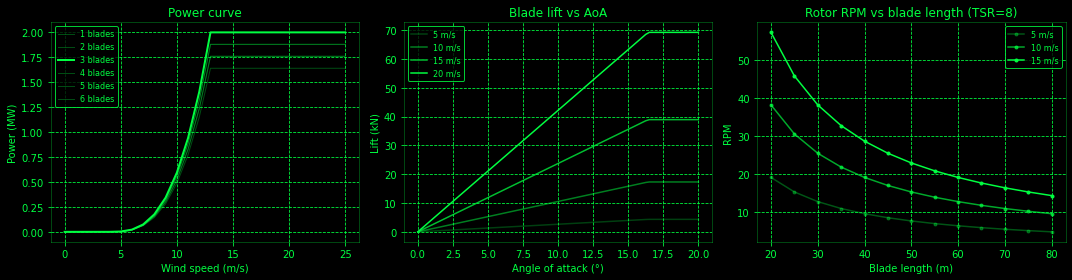

In [5]:
GREEN, DIM, BG = "#00ff41", (0, 1, 0.25, 0.35), "#000"
plt.rcParams.update({
    "figure.facecolor": BG, "axes.facecolor": BG, "axes.edgecolor": DIM,
    "axes.labelcolor": GREEN, "xtick.color": GREEN, "ytick.color": GREEN,
    "text.color": GREEN, "grid.color": (0, 1, 0.25, 0.12), "grid.linestyle": "--",
})

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Power curve vs blade count
for n in range(1, 7):
    w, p = zip(*power_curve(n))
    axes[0].plot(w, p, color=GREEN, alpha=1.0 if n == 3 else 0.3, lw=2 if n == 3 else 1, label=f"{n} blades")
axes[0].set(title="Power curve", xlabel="Wind speed (m/s)", ylabel="Power (MW)")
axes[0].legend(fontsize=8, facecolor=BG, edgecolor=DIM, labelcolor=GREEN)

# Lift vs angle of attack at several wind speeds
aoa = np.linspace(0, 20, 81)
for wind in (5, 10, 15, 20):
    lift = [blade_physics(a, wind, BLADE["blade_length_m"], BLADE["max_chord_m"])["total_lift_n"] / 1e3 for a in aoa]
    axes[1].plot(aoa, lift, color=GREEN, alpha=wind / 20, label=f"{wind} m/s")
axes[1].set(title="Blade lift vs AoA", xlabel="Angle of attack (°)", ylabel="Lift (kN)")
axes[1].legend(fontsize=8, facecolor=BG, edgecolor=DIM, labelcolor=GREEN)

# RPM vs blade length
lengths = np.arange(20, 81, 5)
for wind in (5, 10, 15):
    axes[2].plot(lengths, [blade_physics(8, wind, L, 4.2)["rpm"] for L in lengths], color=GREEN, alpha=wind / 15, marker="o", ms=3, label=f"{wind} m/s")
axes[2].set(title="Rotor RPM vs blade length (TSR=8)", xlabel="Blade length (m)", ylabel="RPM")
axes[2].legend(fontsize=8, facecolor=BG, edgecolor=DIM, labelcolor=GREEN)

for ax in axes:
    ax.grid(True)
plt.tight_layout()
plt.show()

### Animated airfoil sweep (matplotlib)

A NACA 4412 section sweeping angle of attack 0° → 20° → 0°, with lift arrows and $C_L$. Rendered with `FuncAnimation` → JS player, so it works the same in Colab.

In [6]:
def naca4(code="4412", n=120):
    m, p, t = int(code[0]) / 100, int(code[1]) / 10, int(code[2:]) / 100
    x = (1 - np.cos(np.linspace(0, np.pi, n))) / 2
    yt = 5 * t * (0.2969*np.sqrt(x) - 0.1260*x - 0.3516*x**2 + 0.2843*x**3 - 0.1015*x**4)
    yc = np.where(x < p, m / p**2 * (2*p*x - x**2), m / (1-p)**2 * ((1 - 2*p) + 2*p*x - x**2))
    dyc = np.where(x < p, 2*m / p**2 * (p - x), 2*m / (1-p)**2 * (p - x))
    th = np.arctan(dyc)
    xu, yu = x - yt*np.sin(th), yc + yt*np.cos(th)
    xl, yl = x + yt*np.sin(th), yc - yt*np.cos(th)
    return np.concatenate([xu[::-1], xl[1:]]), np.concatenate([yu[::-1], yl[1:]])

AF_X, AF_Y = naca4("4412")
WIND = DEFAULT_WIND
sweep = np.concatenate([np.linspace(0, 20, 40), np.linspace(20, 0, 40)])

fig, ax = plt.subplots(figsize=(8, 4))
ax.set(xlim=(-0.6, 1.6), ylim=(-0.6, 0.8), aspect="equal")
ax.axis("off")
foil, = ax.fill(AF_X, AF_Y, facecolor=(0, 1, 0.25, 0.08), edgecolor=GREEN, lw=1.5)
chord, = ax.plot([0, 1], [0, 0], color=DIM, ls="--", lw=1)
stream_ys = np.array([-0.45, -0.3, -0.15, 0.15, 0.3, 0.45])
stream_x = np.linspace(-0.6, 1.6, 100)
streams = [ax.plot([], [], color=GREEN, alpha=0.35, lw=1)[0] for _ in stream_ys]
lift_xs = np.linspace(0.1, 0.7, 5)
arrows = []
label = ax.text(-0.55, 0.7, "", fontsize=11, family="monospace")

def draw(i):
    a = sweep[i]
    r = np.radians(-a)
    c, s = np.cos(r), np.sin(r)
    px = 0.25  # rotate about quarter chord
    X = px + (AF_X - px) * c - AF_Y * s
    Y = (AF_X - px) * s + AF_Y * c
    foil.set_xy(np.column_stack([X, Y]))
    chord.set_data([px + (0 - px) * c, px + (1 - px) * c], [(0 - px) * s, (1 - px) * s])
    for line, y0 in zip(streams, stream_ys):
        prox = max(0, 1 - abs(y0) / 0.6)
        bump = (0.012 if y0 > 0 else 0.004) * a * prox * np.exp(-((stream_x - 0.4) / 0.5) ** 2)
        line.set_data(stream_x, y0 + np.sign(y0) * bump)
    for arr in arrows:
        arr.remove()
    arrows.clear()
    ph = blade_physics(a, WIND, BLADE["blade_length_m"], BLADE["max_chord_m"])
    L = 0.35 * ph["cl"] / 1.8
    if L > 0.01:
        for x in lift_xs:
            arrows.append(ax.annotate("", xy=(x, 0.12 + L), xytext=(x, 0.12),
                                      arrowprops=dict(arrowstyle="-|>", color=GREEN, lw=2)))
    label.set_text(f"AoA {a:5.1f}°   Cl {ph['cl']:.2f}   Lift {ph['total_lift_n']/1e3:6.1f} kN @ {WIND:g} m/s")
    return [foil, chord, label, *streams, *arrows]

anim = animation.FuncAnimation(fig, draw, frames=len(sweep), interval=60, blit=False)
plt.close(fig)
HTML(anim.to_jshtml())